# Exhaustive interval detection

In [1]:
%matplotlib inline

# Import the analysis and plotting tools and record the package version.
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


Threshold selection: {'matched_events': 0, 'detected_events': 0, 'true_events': 1, 'false_positives': 0, 'missed_events': 1, 'precision': 0.0, 'recall': 0.0}
Ranked events: [{'start': 32, 'stop': 40, 'time_start': 4.324324324324325, 'time_last': 5.27027027027027}, {'start': 64, 'stop': 72, 'time_start': 8.64864864864865, 'time_last': 9.594594594594595}]


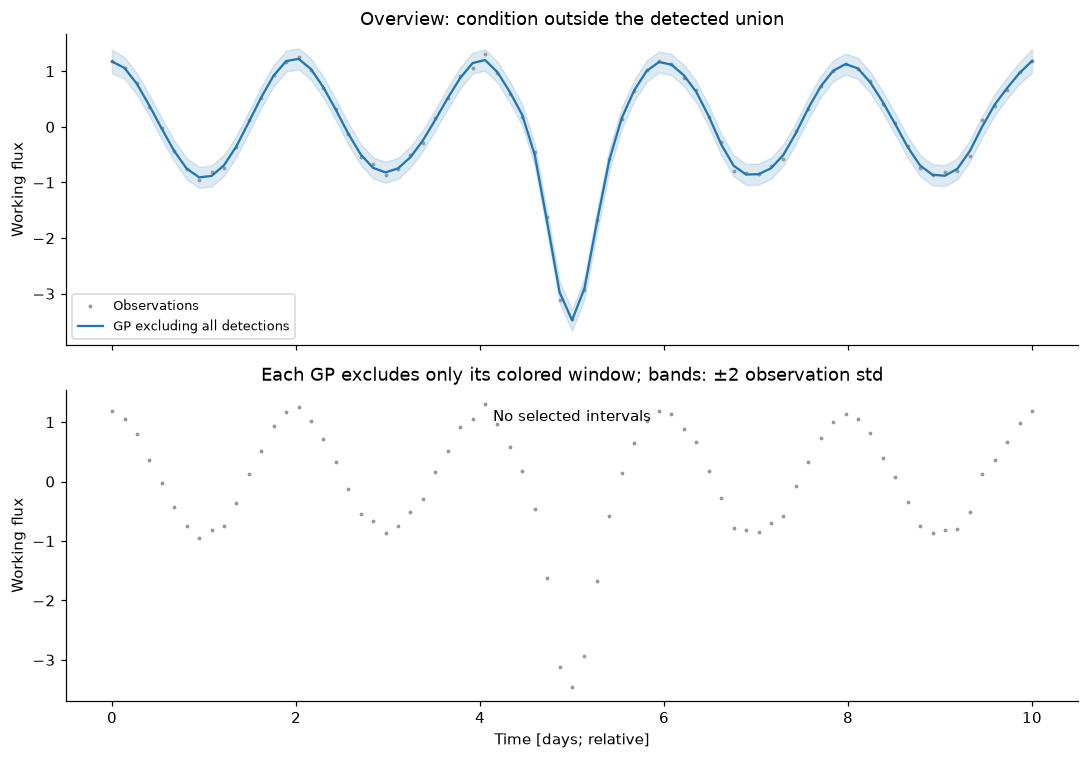

In [2]:
# Generate a periodic baseline and inject one known Gaussian dip.
lc = Nahiku.from_synthetic_noise(n_points=75, red_noise=0, white_noise=.02)
lc.inject_anomaly(center=5, width=.2, depth=.8)

# Standardize the observations and fit the GP used for interval conditioning.
lc.standardize().fit_gp(period=2, iterations=40)

# Score candidate windows with cached-precision conditioning and a p-value cutoff.
# Lengths and steps are sample counts; the default size_step tests lengths 2, 4, 6, and 8.
fast = lc.exhaustive_search(min_points=2, max_points=8, step=4, threshold=1e-6)

# Repeat on the same candidate grid using direct conditioning and fixed hyperparameters.
direct = lc.exhaustive_search(min_points=2, max_points=8, step=4, threshold=1e-6, acceleration=False)

# Verify that both conditioning approaches produce matching candidate scores.
assert np.allclose([c["score"] for c in fast.candidates], [c["score"] for c in direct.candidates])

# Plot the accelerated result and evaluate event recovery against the injected truth.
fast.plot();
print("Threshold selection:", lc.evaluate(fast))

# Alternatively rank non-overlapping windows by Mahalanobis distance without a cutoff.
# top_k limits ranked candidates; it does not establish statistical significance.
ranked = lc.exhaustive_search(min_points=2, max_points=8, step=4, metric="mahalanobis",
                             threshold=None, top_k=2)
print("Ranked events:", ranked.events)

P-value cutoff 1e-3: {'matched_events': 1, 'detected_events': 1, 'true_events': 1, 'false_positives': 0, 'missed_events': 0, 'precision': 1.0, 'recall': 1.0}
Detected events: [{'start': 32, 'stop': 40, 'time_start': 4.324324324324325, 'time_last': 5.27027027027027}]


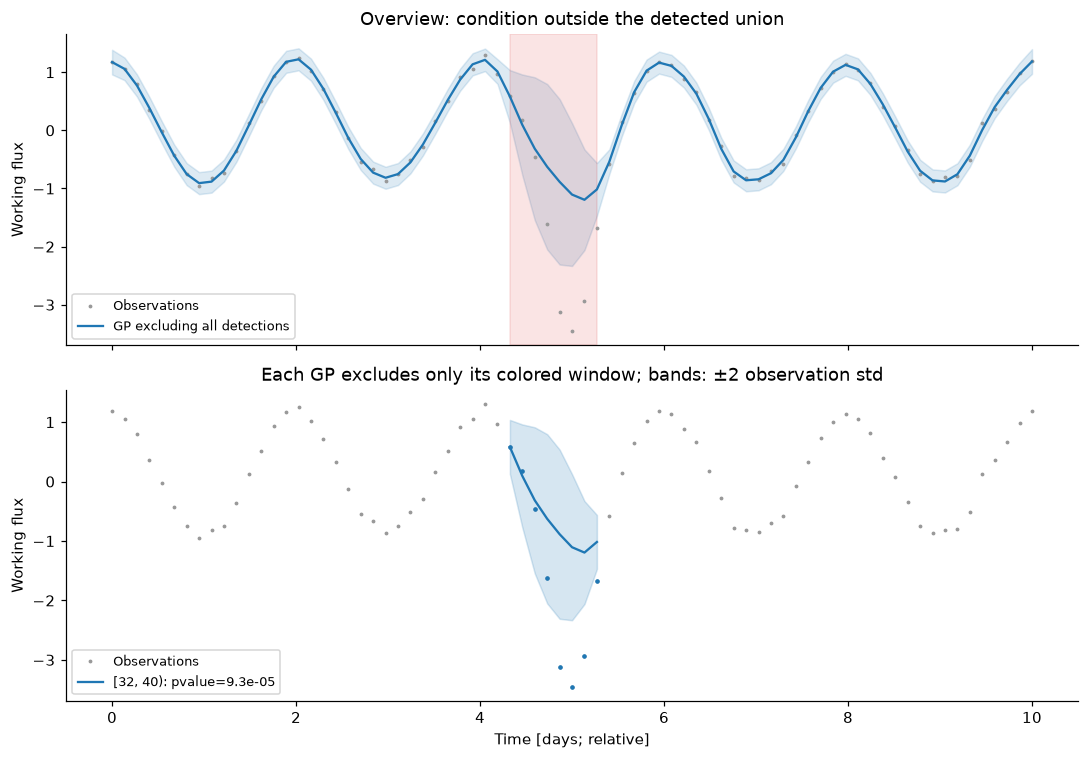

In [3]:
# Relax the significance requirement by increasing the accepted p-value cutoff.
# For p-values, a smaller threshold is stricter; 1e-3 accepts more windows than 1e-6.
relaxed = lc.exhaustive_search(
    min_points=2, max_points=8, step=4, threshold=1e-3,
)

# Plot the detected interval and compare it with the known injected event.
relaxed.plot();
report = lc.evaluate(relaxed)
print("P-value cutoff 1e-3:", report)
print("Detected events:", relaxed.events)

# Verify that the injection is recovered without extra detected events in this example.
assert report["matched_events"] == 1 and report["false_positives"] == 0

The upper panel shows the GP prediction conditioned on observations outside all detected intervals. In the lower panel, each colored curve excludes only its own candidate window. Matching dots identify the excluded observations, and bands show ±2 predictive observation standard deviations. By default, each merged event is represented by its strongest selected candidate, with ties resolved by sample bounds. Use `selection="all"` to show all selected windows, including overlaps. A merged event may span several scored windows. Joint scores use correlations between observations as well as the pointwise uncertainties shown in the bands.

`event_index` selects a merged event by its zero-based index and plots its representative candidate's GP across the full light curve. Other detections remain in the conditioning data. The stored predictions include any candidate-specific refits, so plotting requires no further optimization or live GP. Use `kind="residuals"` to inspect residuals after excluding all detected intervals. Numerical exports include the conditional distributions.

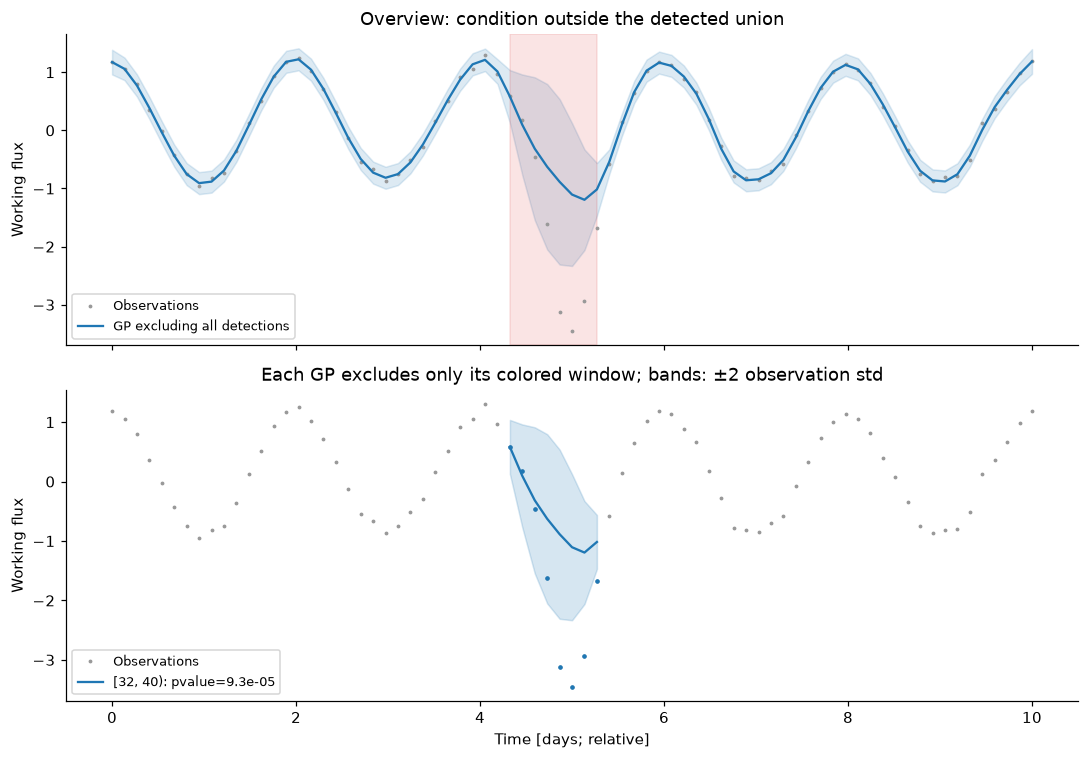

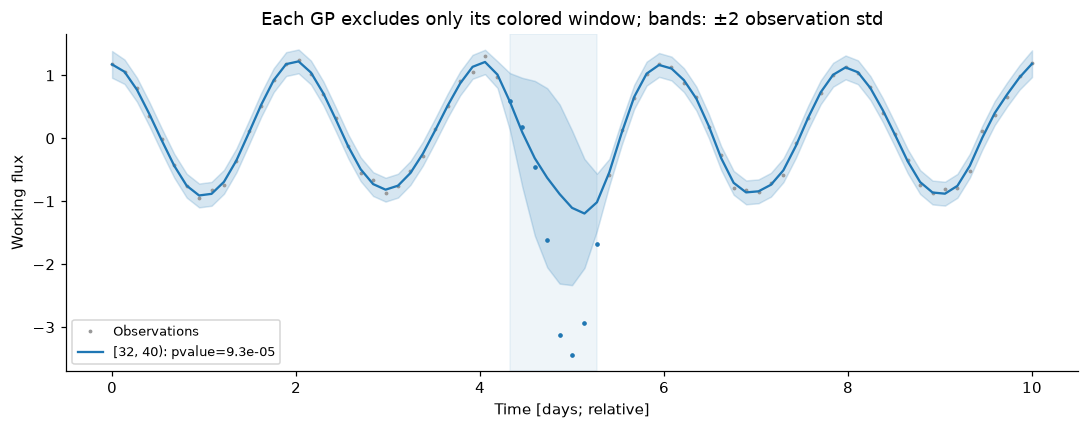

In [4]:
# Inspect the scored conditional fit for one representative window per event.
relaxed.plot(kind="conditional");

# Plot one candidate's GP over the full light curve, excluding only that window.
if relaxed.intervals:
    relaxed.plot(kind="conditional", event_index=0);

# All overlapping selected windows remain accessible with selection="all".
# relaxed.plot(kind="conditional", selection="all");

## Metrics, conditioning, and refits

Torch conditioning is the default. Set `backend="numpy"` for SciPy. Both backends
support cached precision (`acceleration=True`) and direct conditioning (`False`).

Additional scores are `ll` (joint held-out log density), `mll` (mean pointwise
marginal log density), and `msll` (pointwise predictive loss relative to a Gaussian
baseline estimated from retained data). Smaller `ll`/`mll` and larger `msll` indicate
stronger anomalies. Joint `ll` depends on interval length. MLL here differs from
retained-prior marginal likelihood used for greedy growth.

For interval refits, use `refit=True, acceleration=False`. By default,
`warm_initialization=True` starts each interval from the same full-data fitted
parameters. Set it to `False` for fresh initialization. Optimizer state is new.


In [5]:
# Compare three likelihood-based scores on a shared candidate grid.
# Smaller ll/mll and larger msll indicate stronger anomalies; ranking handles the direction.
for metric in ("ll", "mll", "msll"):
    result = lc.exhaustive_search(min_points=3, max_points=8, step=10,
                                  metric=metric, threshold=None, top_k=2)

    # Report merged event intervals as half-open sample indices and the conditioning backend.
    print(metric, result.intervals, result.settings["backend"])

ll [(30, 35), (50, 53)] torch
mll [(30, 35), (60, 67)] torch
msll [(20, 28), (60, 67)] torch


## Interpret the result

Detection depends on the p-value cutoff. A cutoff of `1e-6` selects no events, while `1e-3` recovers the injected dip without additional detected events. Increasing the p-value cutoff relaxes the significance requirement; decreasing it makes selection stricter. The fitted GP and candidate grid are identical in both searches, so the difference comes from selection alone. Event recovery alone does not establish a false-alarm rate or accurate event boundaries.

Mahalanobis ranking with `top_k=2` returns one event overlapping the dip and another away from it. The likelihood-based rankings also vary with their scoring definitions and candidate grid; ranking alone does not establish event recovery.

Exhaustive search evaluates the intervals on the configured candidate grid. Widths and steps are sample counts; `step` controls starting positions and `size_step` controls lengths. The grid includes windows ending at the final observation and the maximum requested length. When either step exceeds one, the search evaluates every window on that grid but omits some possible intervals.

Cached-precision and direct conditioning calculate the same conditional distribution for fixed fitted hyperparameters, up to numerical precision. The assertion compares their candidate scores. Acceleration reuses a precision matrix rather than applying dynamic programming. Both searches use Torch by default, and `backend="numpy"` selects SciPy.

The p-value threshold selects anomalous intervals, while `top_k` ranks up to the requested number of non-overlapping candidates without requiring significance. Adjacent selected candidates can merge into a single reported event. Testing many overlapping windows does not turn the per-window p-value cutoff into a global false-alarm probability. Event recovery also does not guarantee precise event boundaries.

Likelihood scores have different meanings: `ll` is joint held-out log density, `mll` is mean pointwise marginal held-out log density, and `msll` compares pointwise predictive loss with a Gaussian baseline estimated from retained data. Smaller `pvalue`, `ll`, and `mll` indicate stronger anomalies; larger `mahalanobis`, `nlpd`, `msll`, and `rmse` indicate stronger anomalies. Joint log density depends on interval length. Exhaustive `mll` differs from the retained prior marginal likelihood used for greedy growth.

Per-interval hyperparameter refitting requires `refit=True, acceleration=False`. Warm initialization starts each candidate independently from the full-data fit, with a new optimizer state. The overview prediction uses the full-data hyperparameters conditioned outside all detected samples, even when candidate scores use refits. Individual conditional plots retain the predictions used to score their windows. Each returned result remains independent of subsequent searches.

Consult the API reference for parameter and return-value details.